# BTS — Tuning definitivo de LightGBM en AWS (float64)

**A partir del notebook original `flight_delay_tuning.ipynb`, adaptado a los checkpoints reales del proyecto.**

Se conserva el protocolo científico: **40 trials Optuna** (proxy 1M/500K, búsqueda LR=0,1), **TOP_K=3** candidatos entrenados en **4M/1M** con LR=0,03, selección **solo por PR-AUC de validación**, evaluación en prueba, bootstrap y **refit train+val** para el despliegue.

**Cambios operativos:** lee la etapa A (no reejecuta DuckDB/Silver), carga los niveles categóricos del B1 float64, reutiliza el modelo B1 como baseline (no lo entrena de nuevo), persiste estudio SQLite y cada candidato, prepara un modelo `model.tar.gz` con contrato JSON para SageMaker, genera Gold definitivo y permite subir resultados de manera independiente después de renovar credenciales.

**Requisitos:** ejecutar desde `/home/ec2-user/SageMaker/src/`. No ejecutar todo de golpe si el laboratorio tiene un tiempo de sesión limitado: respalda Optuna, confirma modelos por separado y sube a S3 al final. El almacenamiento EBS del notebook debe preservarse entre reinicios del Learner Lab.

**Variable objetivo:** `DepDel15`, retraso de salida de al menos 15 minutos. No se ha entrenado un objetivo de «pérdida de conexión».

In [1]:
%pip install -q numpy pandas scikit-learn matplotlib pyarrow boto3 lightgbm scipy joblib duckdb optuna


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import gc, json, os, time, shutil, sys, sqlite3, tarfile, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import lightgbm as lgb
import optuna
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, log_loss, brier_score_loss
from IPython.display import display

ROOT = Path.cwd()
assert ROOT.name == "src", f"Ejecuta desde SageMaker/src, no desde {ROOT}"
sys.path.insert(0, str((ROOT / "utils").resolve()))
import model_eval as me

PARTS_BASE = Path("../data/checkpoints/features_seed42_h240_chunk50000")
B1_DIR = Path("../outputs/outputs_modeling/checkpoints/lightgbm_float64")
OUT_DIR = Path("../outputs/outputs_modeling/tuning_lightgbm_float64")
CAND_DIR = OUT_DIR / "candidates"
FIG_DIR = OUT_DIR / "figures"
REGISTRY_ROOT = Path("../outputs/model_registry")
GOLD_DIR = Path("../data/gold/pred_vs_real")
for folder in (OUT_DIR, CAND_DIR, FIG_DIR, REGISTRY_ROOT): folder.mkdir(parents=True, exist_ok=True)

SEED = 42
TARGET = "DepDel15"
BUCKET = "bts-flights-analysis"
S3_TUNING_PREFIX = "modeling/tuning/lightgbm-float64-seed42-h240/"
S3_B1_PREFIX = "modeling/checkpoints/lightgbm-float64-original-seed42-h240/"
N_TRAIN, N_EVAL = 4_000_000, 1_000_000
N_TUNE_TRAIN, N_TUNE_VAL = 1_000_000, 500_000
SEARCH_LR, SEARCH_MAX_TREES, SEARCH_EARLY_STOP = 0.1, 1500, 50
N_TRIALS, TIMEOUT_MIN = 40, 75
TOP_K, FINAL_LR, FINAL_MAX_TREES, FINAL_EARLY_STOP = 3, 0.03, 4000, 100
RUN_REFIT = True
COST_FP, COST_FN = 1, 3
BOOT_ROWS, BOOT_N = 300_000, 100
OPTUNA_DB = OUT_DIR / "study.sqlite3"
# Si no está la base local (instancia recreada), intentar recuperar snapshot de S3.
if not OPTUNA_DB.exists():
    try:
        import boto3
        boto3.Session().client("s3").download_file(
            "bts-flights-analysis", "modeling/tuning/lightgbm-float64-seed42-h240/study_backup.sqlite3", str(OPTUNA_DB))
        print("✔ Estudio Optuna recuperado desde S3")
    except Exception:
        print("No hay estudio SQLite local recuperable; se empezará uno nuevo si no existe backup")
RUN_ID_FILE = OUT_DIR / "run_id.txt"
if RUN_ID_FILE.exists():
    RUN_ID = RUN_ID_FILE.read_text().strip()
else:
    RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    RUN_ID_FILE.write_text(RUN_ID)

print("Run ID:", RUN_ID, "| carpeta:", OUT_DIR.resolve())
print("Disco libre (GiB):", round(shutil.disk_usage(ROOT).free / 1024**3, 2))
print("LightGBM:", lgb.__version__, "Optuna:", optuna.__version__)

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


No hay estudio SQLite local recuperable; se empezará uno nuevo si no existe backup
Run ID: 20261122T031926Z | carpeta: /home/ec2-user/SageMaker/outputs/outputs_modeling/tuning_lightgbm_float64
Disco libre (GiB): 25.25
LightGBM: 4.7.0 Optuna: 5.1.0


## 1. Verificar etapa A y recuperar baseline B1 float64

Solo se descargan los pequeños archivos de **B1**, no se descargan ni regeneran los millones de registros. Si el laboratorio pierde credenciales, recupera B1 después de reiniciarlo.

In [4]:
for split, expected in (("train", N_TRAIN), ("val", N_EVAL), ("test", N_EVAL)):
    folder = PARTS_BASE / split
    files = sorted(folder.glob("part_*.parquet"))
    assert (folder / "_SUCCESS").exists() and files, f"La etapa A no está terminada: {folder}"
    actual = sum(pq.ParquetFile(file).metadata.num_rows for file in files)
    assert actual == expected, f"Filas de {split}: {actual:,} != {expected:,}"
    print(f"✔ {split}: {len(files)} bloques / {actual:,} filas")

REQUIRED_B1 = ["feature_schema.json", "model.txt", "val_predictions.npz", "test_predictions.npz", "run_config.json"]
missing = [name for name in REQUIRED_B1 if not (B1_DIR / name).is_file()]
if missing:
    import boto3
    s3 = boto3.Session().client("s3")
    B1_DIR.mkdir(parents=True, exist_ok=True)
    for name in missing:
        s3.download_file(BUCKET, S3_B1_PREFIX + name, str(B1_DIR / name))
        print("Recuperado B1:", name)

schema = json.loads((B1_DIR / "feature_schema.json").read_text())
FULL = schema["feature_names"]
CAT_COLS = schema["cat_cols"]
CAT_LEVELS = schema["cat_levels"]
NUMERIC_COLS = [c for c in FULL if c not in CAT_COLS]
assert len(FULL) == len(set(FULL)) and set(CAT_COLS).issubset(FULL)
assert set(CAT_LEVELS) == set(CAT_COLS)
assert schema["prediction_horizon_min"] == 240
assert set(FULL + [TARGET, "FlightDate", "dep_hour"]).issubset(pq.ParquetFile(sorted((PARTS_BASE / 'test').glob('part_*.parquet'))[0]).schema_arrow.names)

with np.load(B1_DIR / "val_predictions.npz") as z:
    Y_B1_VAL, P_B1_VAL = z["y"].copy(), z["p"].copy()
with np.load(B1_DIR / "test_predictions.npz") as z:
    Y_B1_TEST, P_B1_TEST = z["y"].copy(), z["p"].copy()
BASELINE_MODEL = lgb.Booster(model_file=str(B1_DIR / "model.txt"))
BASELINE_ROUNDS = int(json.loads((B1_DIR / "run_config.json").read_text())["best_iteration"])
assert BASELINE_MODEL.feature_name() == FULL, "El orden del esquema no coincide con el modelo B1"
print(f"✔ B1 float64: {BASELINE_ROUNDS} árboles | PR-AUC val = {average_precision_score(Y_B1_VAL, P_B1_VAL):.6f}")

✔ train: 80 bloques / 4,000,000 filas
✔ val: 20 bloques / 1,000,000 filas
✔ test: 20 bloques / 1,000,000 filas
✔ B1 float64: 930 árboles | PR-AUC val = 0.528347


## 2. Lectura compacta y reproducible de Stage A

No se reconstruyen variables desde Silver; se cargan los **mismos** fragmentos que B1. El dtype numérico es float64 y las categóricas utilizan el orden exacto de niveles del checkpoint. `train` y `val` permanecen disponibles para la etapa 2. El conjunto `test` **no se carga antes de seleccionar por validación**.

In [5]:
def load_compact(split, extra=None):
    t0 = time.time()
    extras = [c for c in (extra or []) if c not in FULL and c != TARGET]
    cols = FULL + [TARGET] + extras
    frames = []
    paths = sorted((PARTS_BASE / split).glob("part_*.parquet"))
    for i, path in enumerate(paths, 1):
        frame = pd.read_parquet(path, columns=cols)
        for col in NUMERIC_COLS:
            frame[col] = pd.to_numeric(frame[col], errors="coerce").astype(np.float64)
        for col in CAT_COLS:
            frame[col] = pd.Categorical(frame[col], categories=CAT_LEVELS[col])
        frame[TARGET] = frame[TARGET].astype(np.uint8)
        frames.append(frame)
        if i % 20 == 0: print(f" {split}: {i}/{len(paths)} fragmentos")
    result = pd.concat(frames, ignore_index=True)
    del frames; gc.collect()
    print(f"✔ {split}: {len(result):,} filas / {result.memory_usage(deep=True).sum()/1024**3:.2f} GiB / {time.time()-t0:.1f}s")
    return result

train_df = load_compact("train")
val_df = load_compact("val")
y_train = train_df.pop(TARGET).to_numpy(dtype=np.uint8, copy=True)
y_val = val_df.pop(TARGET).to_numpy(dtype=np.uint8, copy=True)
assert np.array_equal(y_val, Y_B1_VAL), "Muestra de validación distinta del checkpoint B1"
assert list(train_df.columns) == list(val_df.columns) == FULL
assert all(train_df[k].dtype == np.float64 for k in NUMERIC_COLS)
# Comprobación de esquema y categorías versus las predicciones reales de B1.
probe = BASELINE_MODEL.predict(val_df.iloc[:100])
assert np.allclose(probe, P_B1_VAL[:100], atol=1e-7), "La matriz no reproduce B1 float64"
print("✔ B1 reproduce sus probabilidades; prevalencias:",y_train.mean(),y_val.mean())

 train: 20/80 fragmentos
 train: 40/80 fragmentos
 train: 60/80 fragmentos
 train: 80/80 fragmentos
✔ train: 4,000,000 filas / 0.94 GiB / 8.9s
 val: 20/20 fragmentos
✔ val: 1,000,000 filas / 0.23 GiB / 1.9s
✔ B1 reproduce sus probabilidades; prevalencias: 0.208977 0.222704


## 3. Optuna — 40 trials sobre muestra proxy (1M / 500K)

Se mantiene exactamente el espacio de búsqueda original, métrica objetivo PR-AUC y poda. Optuna se almacena en **SQLite** para continuar después de cierres de sesión. No disminuyas `N_TRIALS` si quieres reproducir la metodología original. El límite de 75 minutos aplica **por ejecución**; si no llega a 40 trials, ejecuta de nuevo la celda de búsqueda. Los resultados ya terminados no se repiten.

La primera prueba usa los hiperparámetros de referencia expresados como fracciones para el proxy; no es exactamente B1 entrenado con 4M. La comparación real con B1 se hace después.

In [7]:
BASE = dict(objective="binary", bagging_freq=1, max_cat_to_onehot=4, verbosity=-1, seed=SEED, num_threads=4)
BASELINE_PARAMS = dict(
    learning_rate=0.03, num_leaves=63, max_depth=-1, min_data_in_leaf=2000,
    feature_fraction=0.7, bagging_fraction=0.8, lambda_l1=0.0, lambda_l2=20.0,
    min_gain_to_split=0.0, path_smooth=0.0, cat_smooth=100.0, cat_l2=10.0,
    min_data_per_group=500, max_cat_threshold=32,
)
DS_PARAMS = {"feature_pre_filter": False, "max_bin": 255}

def make_datasets(train_X, train_y, valid_X=None, valid_y=None):
    dtr = lgb.Dataset(train_X, label=train_y, params=DS_PARAMS, free_raw_data=False)
    dva = None if valid_X is None else lgb.Dataset(valid_X, label=valid_y, reference=dtr, free_raw_data=False)
    return dtr, dva

def to_params(p, n_rows, lr):
    return dict(learning_rate=lr, num_leaves=int(p["num_leaves"]), max_depth=int(p["max_depth"]),
        min_data_in_leaf=max(20, int(p["min_child_frac"] * n_rows)),
        feature_fraction=float(p["feature_fraction"]), bagging_fraction=float(p["bagging_fraction"]),
        lambda_l1=float(p["lambda_l1"]), lambda_l2=float(p["lambda_l2"]),
        min_gain_to_split=float(p["min_split_gain"]), path_smooth=float(p["path_smooth"]),
        cat_smooth=float(p["cat_smooth"]), cat_l2=float(p["cat_l2"]),
        min_data_per_group=int(p["min_data_per_group"]), max_cat_threshold=int(p["max_cat_threshold"]))

tr_t = train_df.sample(min(N_TUNE_TRAIN, len(train_df)), random_state=SEED)
va_t = val_df.sample(min(N_TUNE_VAL, len(val_df)), random_state=SEED)
ytr_t = y_train[tr_t.index.to_numpy()]
yva_t = y_val[va_t.index.to_numpy()]
proxy_train, proxy_val = make_datasets(tr_t, ytr_t, va_t, yva_t)
print(f"Proxy: {len(tr_t):,} train / {len(va_t):,} val")

def suggest(trial):
    return dict(
        num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
        max_depth=trial.suggest_categorical("max_depth", [-1, 6, 8, 10, 12]),
        min_child_frac=trial.suggest_float("min_child_frac", 5e-5, 3e-3, log=True),
        feature_fraction=trial.suggest_float("feature_fraction", 0.4, 1.0),
        bagging_fraction=trial.suggest_float("bagging_fraction", 0.5, 1.0),
        lambda_l1=trial.suggest_float("lambda_l1", 1e-3, 50.0, log=True),
        lambda_l2=trial.suggest_float("lambda_l2", 1e-2, 200.0, log=True),
        min_split_gain=trial.suggest_float("min_split_gain", 0.0, 0.5),
        path_smooth=trial.suggest_float("path_smooth", 0.0, 50.0),
        cat_smooth=trial.suggest_float("cat_smooth", 5.0, 200.0, log=True),
        cat_l2=trial.suggest_float("cat_l2", 1.0, 100.0, log=True),
        min_data_per_group=trial.suggest_int("min_data_per_group", 50, 2000, log=True),
        max_cat_threshold=trial.suggest_int("max_cat_threshold", 8, 128, log=True))

def prune_callback(trial, every=25):
    def _cb(env):
        if (env.iteration + 1) % every: return
        for _, metric, value, _ in env.evaluation_result_list:
            if metric == "average_precision":
                trial.report(value, env.iteration + 1)
                if trial.should_prune(): raise optuna.TrialPruned()
    return _cb

def objective(trial):
    params = {**BASE, **to_params(suggest(trial), len(tr_t), SEARCH_LR),
              "metric": ["average_precision", "binary_logloss"]}
    bst = lgb.train(params, proxy_train, num_boost_round=SEARCH_MAX_TREES,
        valid_sets=[proxy_val], valid_names=["val"],
        callbacks=[lgb.early_stopping(SEARCH_EARLY_STOP, first_metric_only=True, verbose=False),
                   prune_callback(trial)])
    trial.set_user_attr("best_iter", int(bst.best_iteration))
    trial.set_user_attr("val_logloss", float(bst.best_score["val"]["binary_logloss"]))
    return float(bst.best_score["val"]["average_precision"])

storage_uri = f"sqlite:///{OPTUNA_DB.resolve().as_posix()}"
study = optuna.create_study(
    study_name="lightgbm_float64_seed42_h240",
    storage=storage_uri, load_if_exists=True, direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=10),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=100))
if len(study.trials) == 0:
    study.enqueue_trial(dict(num_leaves=63, max_depth=-1, min_child_frac=2000/N_TRAIN,
        feature_fraction=0.7, bagging_fraction=0.8, lambda_l1=1e-3, lambda_l2=20.0,
        min_split_gain=0.0, path_smooth=0.0, cat_smooth=100.0, cat_l2=10.0,
        min_data_per_group=500, max_cat_threshold=32))
print(f"Trials ya registrados: {len(study.trials)} / {N_TRIALS}")

[I 2026-11-22 03:21:30,767] Using an existing study with `study_name='lightgbm_float64_seed42_h240'` instead of creating a new one.


Proxy: 1,000,000 train / 500,000 val
Trials ya registrados: 1 / 40


### Ejecutar búsqueda y guardar automáticamente el estado

Cada trial queda confirmado en SQLite; cada 5 trials se genera una copia consistente (`sqlite3.backup`). El respaldo opcional S3 no debe detener el tuning cuando caducan credenciales. Si reinicias el laboratorio, repite las celdas hasta aquí y vuelve a ejecutar la siguiente **sin eliminar `study.sqlite3`**.

In [8]:
import boto3

def snapshot_sqlite():
    destination = OUT_DIR / "study_backup.sqlite3"
    with sqlite3.connect(str(OPTUNA_DB)) as src:
        with sqlite3.connect(str(destination)) as dst:
            src.backup(dst)
    return destination

def after_trial(study, trial):
    total = len(study.trials)
    if total % 5: return
    snapshot = snapshot_sqlite()
    print(f"✔ Optuna guardado: {total} trials | {snapshot}")
    try:
        s3 = boto3.Session().client("s3")
        s3.upload_file(str(snapshot), BUCKET, S3_TUNING_PREFIX + "study_backup.sqlite3")
        print("  Copia S3 completada")
    except Exception as err:
        print("  Sin S3 por ahora (resultados locales intactos):", type(err).__name__)

finished = sum(t.state.is_finished() for t in study.trials)
remaining = max(0, N_TRIALS - finished)
if remaining:
    start = time.time()
    study.optimize(objective, n_trials=remaining, timeout=TIMEOUT_MIN*60,
                   callbacks=[after_trial], gc_after_trial=True)
    print(f"Sesión Optuna: {(time.time()-start)/60:.1f} min")
else:
    print("✔ Los 40 trials ya están registrados; no se repite la búsqueda")
snapshot_sqlite()
print("Estados:", pd.Series([t.state.name for t in study.trials]).value_counts().to_dict())
print("Finalizados:", sum(t.state.is_finished() for t in study.trials), "de", N_TRIALS)

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/lightgbm/basic.py:2515: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")
[I 2026-11-22 03:24:05,004] Trial 0 finished with value: 0.5222451901998797 and parameters: {'num_leaves': 63, 'max_depth': -1, 'min_child_frac': 0.0005, 'feature_fraction': 0.7, 'bagging_fraction': 0.8, 'lambda_l1': 0.001, 'lambda_l2': 20.0, 'min_split_gain': 0.0, 'path_smooth': 0.0, 'cat_smooth': 100.0, 'cat_l2': 10.0, 'min_data_per_group': 500, 'max_cat_threshold': 32}. Best is trial 0 with value: 0.5222451901998797.
[I 2026-11-22 03:24:36,223] Trial 1 finished with value: 0.5159930165588832 and parameters: {'num_leaves': 42, 'max_depth': -1, 'min_child_frac': 6.342368214226899e-05, 'feature_fraction': 0.9197056874649611, 'bagging_fraction': 0.8005575058716043, 'lambda_l1': 2.124280213720889, 'lambda_l2': 0.012261243785158804, 'min_split_gain': 0.48495492608099716,

✔ Optuna guardado: 5 trials | ../outputs/outputs_modeling/tuning_lightgbm_float64/study_backup.sqlite3
  Copia S3 completada


[I 2026-11-22 03:27:14,949] Trial 5 finished with value: 0.5192793790786259 and parameters: {'num_leaves': 18, 'max_depth': -1, 'min_child_frac': 0.0009033775094656357, 'feature_fraction': 0.8374043008245924, 'bagging_fraction': 0.8856351733429728, 'lambda_l1': 0.0022280944532589255, 'lambda_l2': 0.3481543700948273, 'min_split_gain': 0.05793452976256486, 'path_smooth': 43.155171293779674, 'cat_smooth': 49.83460221146933, 'cat_l2': 4.589824181495649, 'min_data_per_group': 63, 'max_cat_threshold': 18}. Best is trial 0 with value: 0.5222451901998797.
[I 2026-11-22 03:27:34,778] Trial 6 finished with value: 0.5115809286050986 and parameters: {'num_leaves': 37, 'max_depth': 8, 'min_child_frac': 0.000927314636360635, 'feature_fraction': 0.8564710291701385, 'bagging_fraction': 0.7806385987847482, 'lambda_l1': 4.195190175255903, 'lambda_l2': 1.3299327221489687, 'min_split_gain': 0.26136641469099703, 'path_smooth': 21.37705091792748, 'cat_smooth': 5.491525066424377, 'cat_l2': 1.6435497475111325

✔ Optuna guardado: 10 trials | ../outputs/outputs_modeling/tuning_lightgbm_float64/study_backup.sqlite3
  Copia S3 completada


[I 2026-11-22 03:30:04,549] Trial 10 pruned. 
[I 2026-11-22 03:30:16,686] Trial 11 pruned. 
[I 2026-11-22 03:30:30,407] Trial 12 pruned. 
[I 2026-11-22 03:30:43,732] Trial 13 pruned. 
[I 2026-11-22 03:31:09,815] Trial 14 finished with value: 0.5222816003251928 and parameters: {'num_leaves': 57, 'max_depth': 6, 'min_child_frac': 0.00022199594768320806, 'feature_fraction': 0.4583505494668294, 'bagging_fraction': 0.9017385819435191, 'lambda_l1': 0.008299777862188579, 'lambda_l2': 12.983034280000574, 'min_split_gain': 0.3947189812719773, 'path_smooth': 40.58691189016474, 'cat_smooth': 73.17702884484514, 'cat_l2': 32.003986548280345, 'min_data_per_group': 140, 'max_cat_threshold': 101}. Best is trial 8 with value: 0.52478045588845.


✔ Optuna guardado: 15 trials | ../outputs/outputs_modeling/tuning_lightgbm_float64/study_backup.sqlite3
  Copia S3 completada


... (6 outputs left out)

[I 2026-11-22 03:39:13,392] Trial 30 pruned. 
[I 2026-11-22 03:40:15,502] Trial 31 finished with value: 0.5273968757569926 and parameters: {'num_leaves': 85, 'max_depth': 6, 'min_child_frac': 0.0003119300519446779, 'feature_fraction': 0.8477332717095534, 'bagging_fraction': 0.7951761684155662, 'lambda_l1': 0.0052526641600567255, 'lambda_l2': 0.6767780360013287, 'min_split_gain': 0.2121150640406333, 'path_smooth': 11.31765155746373, 'cat_smooth': 8.848145113618544, 'cat_l2': 1.8915723575668661, 'min_data_per_group': 1206, 'max_cat_threshold': 8}. Best is trial 31 with value: 0.5273968757569926.
[I 2026-11-22 03:41:09,914] Trial 32 finished with value: 0.5264983392262251 and parameters: {'num_leaves': 56, 'max_depth': 6, 'min_child_frac': 0.0005154069067372835, 'feature_fraction': 0.8768746103753822, 'bagging_fraction': 0.8020121597336743, 'lambda_l1': 0.007383941620186367, 'lambda_l2': 2.6468631972661147, 'min_split_gain': 0.23865940380192502, 'path_smooth': 21.165283338387123, 'cat_smo

✔ Optuna guardado: 35 trials | ../outputs/outputs_modeling/tuning_lightgbm_float64/study_backup.sqlite3
  Copia S3 completada


[I 2026-11-22 03:42:23,297] Trial 35 pruned. 
[I 2026-11-22 03:43:06,740] Trial 36 pruned. 
[I 2026-11-22 03:43:21,249] Trial 37 pruned. 
[I 2026-11-22 03:44:28,537] Trial 38 finished with value: 0.5274838380796706 and parameters: {'num_leaves': 80, 'max_depth': 6, 'min_child_frac': 0.00017639383821707822, 'feature_fraction': 0.8616250443285667, 'bagging_fraction': 0.9033781962534061, 'lambda_l1': 0.00899891823786102, 'lambda_l2': 0.4641159416741083, 'min_split_gain': 0.2885943180744666, 'path_smooth': 17.47811484121472, 'cat_smooth': 6.777097126076148, 'cat_l2': 1.0937952298316842, 'min_data_per_group': 1527, 'max_cat_threshold': 9}. Best is trial 38 with value: 0.5274838380796706.
[I 2026-11-22 03:44:42,467] Trial 39 pruned. 


✔ Optuna guardado: 40 trials | ../outputs/outputs_modeling/tuning_lightgbm_float64/study_backup.sqlite3
  Copia S3 completada
Sesión Optuna: 21.6 min
Estados: {'PRUNED': 21, 'COMPLETE': 19}
Finalizados: 40 de 40


## 4. Resultados del estudio y gráficas

**Importante:** si aún no hay 40 trials registrados, **no pases a la confirmación**; vuelve a ejecutar la celda de búsqueda cuando se renueve la sesión.

In [9]:
assert sum(t.state.is_finished() for t in study.trials) >= N_TRIALS,     f"Faltan trials: {sum(t.state.is_finished() for t in study.trials)} de {N_TRIALS}. Reanuda Optuna"
trials = study.trials_dataframe(attrs=("number", "value", "state", "user_attrs", "params"))
trials.columns = [col.replace("params_", "").replace("user_attrs_", "") for col in trials.columns]
done = trials.loc[trials.state == "COMPLETE"].sort_values("value", ascending=False)
assert len(done) > 1, "Optuna terminó sin suficientes candidatos completos"
trials.to_csv(OUT_DIR / "tuning_trials.csv", index=False)
print("Mejor PR-AUC proxy:", round(done.value.iloc[0], 6), "| Trials completos:", len(done))
display(done.head(10))
# Liberar 1M + 500K extra antes de entrenar sobre 4M.
del tr_t, va_t, ytr_t, yva_t, proxy_train, proxy_val
gc.collect()

Mejor PR-AUC proxy: 0.527484 | Trials completos: 19


,number,value,state,best_iter,val_logloss,bagging_fraction,cat_l2,cat_smooth,feature_fraction,lambda_l1,lambda_l2,max_cat_threshold,max_depth,min_child_frac,min_data_per_group,min_split_gain,num_leaves,path_smooth
38,38,0.527484,COMPLETE,441.0,0.449479,0.903378,1.093795,6.777097,0.861625,0.008999,0.464116,9,6,0.000176,1527,0.288594,80,17.478115
31,31,0.527397,COMPLETE,459.0,0.449471,0.795176,1.891572,8.848145,0.847733,0.005253,0.676778,8,6,0.000312,1206,0.212115,85,11.317652
26,26,0.526771,COMPLETE,459.0,0.449661,0.780554,2.566495,7.710253,0.861260,0.001255,0.884071,11,6,0.000461,1519,0.272669,49,8.612103
32,32,0.526498,COMPLETE,370.0,0.449806,0.802012,1.045874,15.551244,0.876875,0.007384,2.646863,8,6,0.000515,1435,0.238659,56,21.165283
27,27,0.526405,COMPLETE,360.0,0.449815,0.817460,2.413874,8.294059,0.940754,0.029606,1.741611,10,6,0.000667,1575,0.272424,44,15.631330
24,24,0.525348,COMPLETE,386.0,0.450285,0.857860,1.858342,9.369715,0.899408,0.006664,16.735272,13,12,0.000378,1131,0.230821,37,20.695424
8,8,0.524780,COMPLETE,255.0,0.450661,0.930365,4.734023,7.780393,0.890809,0.001078,1.573039,19,6,0.000287,1620,0.208706,68,11.105391
17,17,0.524667,COMPLETE,469.0,0.450533,0.734684,3.302868,5.978770,0.952470,0.009025,7.171101,10,6,0.000688,513,0.172774,47,22.216470
7,7,0.524316,COMPLETE,479.0,0.450671,0.644876,40.489662,124.480737,0.446188,0.005722,99.691353,95,6,0.000128,99,0.404060,36,31.670188
22,22,0.524021,COMPLETE,252.0,0.450720,0.783408,3.698111,5.092724,0.912643,0.005867,6.645516,14,6,0.000916,283,0.199062,155,25.146491


33694

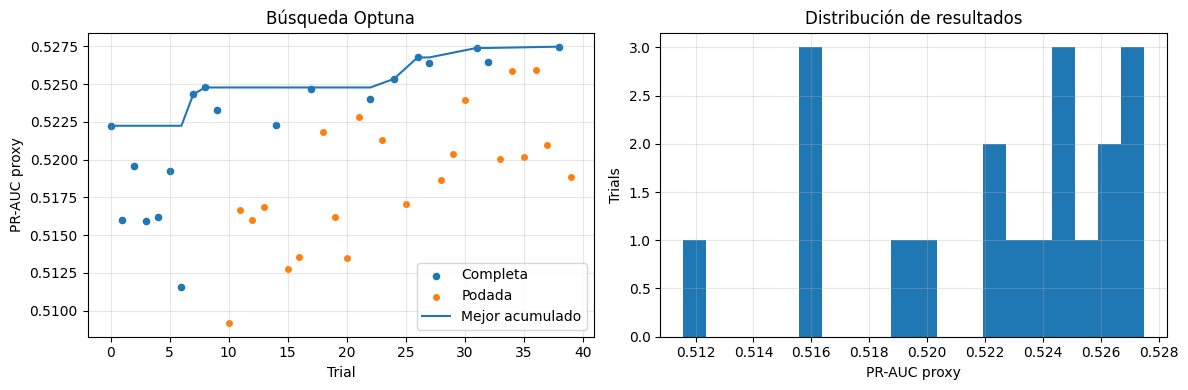

In [10]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
complete = trials.loc[trials.state == "COMPLETE"].sort_values("number")
pruned = trials.loc[trials.state == "PRUNED"].sort_values("number")
ax[0].scatter(complete.number, complete.value, s=20, label="Completa")
ax[0].scatter(pruned.number, pruned.value, s=16, label="Podada")
ax[0].plot(complete.number, complete.value.cummax(), label="Mejor acumulado")
ax[0].set(xlabel="Trial",ylabel="PR-AUC proxy",title="Búsqueda Optuna")
ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].hist(complete.value.dropna(), bins=20)
ax[1].set(xlabel="PR-AUC proxy", ylabel="Trials", title="Distribución de resultados")
ax[1].grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIG_DIR/"optuna_trials.png",dpi=130); plt.show()

## 5. Confirmación con 4M train + 1M val — TOP_K = 3

Se vuelve a entrenar **solo** cada candidato ajustado. El LightGBM original B1 se evalúa a partir de sus predicciones existentes. Cada candidato se guarda inmediatamente en disco con `_SUCCESS`, permitiendo continuar sin repetir los finalizados. **Esta sección aún no usa test.**

In [11]:
full_train, full_val = make_datasets(train_df, y_train, val_df, y_val)

def fit_or_load_trial(trial_no, params):
    name = f"trial_{trial_no:03d}"
    folder = CAND_DIR / name
    folder.mkdir(parents=True, exist_ok=True)
    required = ["model.txt", "val_predictions.npz", "run_config.json", "_SUCCESS"]
    if all((folder / f).exists() for f in required):
        bst = lgb.Booster(model_file=str(folder / "model.txt"))
        with np.load(folder / "val_predictions.npz") as z:
            assert np.array_equal(z["y"], y_val), f"Etiquetas incompatibles para {name}"
            p_val = z["p"].copy()
        metadata = json.loads((folder / "run_config.json").read_text())
        print("✔ Recuperado, sin entrenar:", name)
        return {"name":name, "trial":int(trial_no), "params":params, "booster":bst,
                "p_val":p_val, "best_iteration":int(metadata["best_iteration"]), "seconds":metadata["seconds"]}

    t0 = time.time()
    run_params = {**BASE, **params, "metric": ["binary_logloss", "average_precision"]}
    evals={}
    bst = lgb.train(run_params, full_train, num_boost_round=FINAL_MAX_TREES,
        valid_sets=[full_val], valid_names=["val"],
        callbacks=[lgb.early_stopping(FINAL_EARLY_STOP, first_metric_only=True, verbose=False),
                   lgb.record_evaluation(evals)])
    (folder / "learning_curve.json").write_text(json.dumps(evals,default=float))
    duration = round(time.time()-t0,2)
    p_val = bst.predict(val_df, num_iteration=bst.best_iteration)
    bst.save_model(str(folder / "model.txt"))
    np.savez_compressed(folder / "val_predictions.npz", y=y_val, p=p_val)
    record = {"name": name,"trial":int(trial_no),"params":params,"seed":SEED,"numeric_dtype":"float64",
        "train_rows":len(train_df),"val_rows":len(val_df),"best_iteration":int(bst.best_iteration),
        "seconds":duration, "val_pr_auc":float(average_precision_score(y_val,p_val)),
        "early_stop_metric":"binary_logloss", "input_checkpoint":"stage_A_seed42_h240"}
    (folder / "run_config.json").write_text(json.dumps(record,indent=2,default=float))
    (folder / "_SUCCESS").write_text("ok\n")
    print(f"✔ {name}: {bst.best_iteration} árboles | PR-AUC val {record['val_pr_auc']:.6f} | {duration}s")
    return {"name":name,"trial":int(trial_no),"params":params,"booster":bst,
            "p_val":p_val,"best_iteration":int(bst.best_iteration),"seconds":duration}

candidates = [{"name":"B1_baseline_float64", "trial":None, "params":BASELINE_PARAMS,
               "booster":BASELINE_MODEL, "p_val":P_B1_VAL,
               "best_iteration":BASELINE_ROUNDS, "seconds":716.6}]

top = done.loc[done.number != 0].head(TOP_K)
assert len(top) == TOP_K, "No hay TOP_K trials distintos del de referencia"
for rank, (_, row) in enumerate(top.iterrows(),1):
    p = {k:row[k] for k in ["num_leaves","max_depth","min_child_frac","feature_fraction",
        "bagging_fraction","lambda_l1","lambda_l2","min_split_gain","path_smooth","cat_smooth",
        "cat_l2","min_data_per_group","max_cat_threshold"]}
    params = to_params(p, N_TRAIN, FINAL_LR)
    candidates.append(fit_or_load_trial(int(row.number), params))

stage2 = pd.DataFrame([{"modelo":c["name"], "trial":c["trial"], "best_iteration":c["best_iteration"],
    "seconds":c["seconds"],"pr_auc_val":average_precision_score(y_val,c["p_val"]),
    "roc_auc_val":roc_auc_score(y_val,c["p_val"]),
    "log_loss_val":log_loss(y_val,c["p_val"]),"brier_val":brier_score_loss(y_val,c["p_val"])}
    for c in candidates]).set_index("modelo")
print("Comparación de validación:")
display(stage2.sort_values("pr_auc_val",ascending=False))
stage2.to_csv(OUT_DIR/"tuning_validation_comparison.csv")
del full_train, full_val
gc.collect()

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/lightgbm/basic.py:2515: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")


✔ trial_038: 1963 árboles | PR-AUC val 0.531838 | 840.97s
✔ trial_031: 1700 árboles | PR-AUC val 0.531246 | 697.87s
✔ trial_026: 2204 árboles | PR-AUC val 0.531035 | 841.82s
Comparación de validación:


,trial,best_iteration,seconds,pr_auc_val,roc_auc_val,log_loss_val,brier_val
modelo,,,,,,,
trial_038,38.0,1963,840.97,0.531838,0.754643,0.446931,0.141753
trial_031,31.0,1700,697.87,0.531246,0.754443,0.447099,0.141800
trial_026,26.0,2204,841.82,0.531035,0.754243,0.447206,0.141824
B1_baseline_float64,NaN,930,716.60,0.528347,0.752496,0.448349,0.142244


184

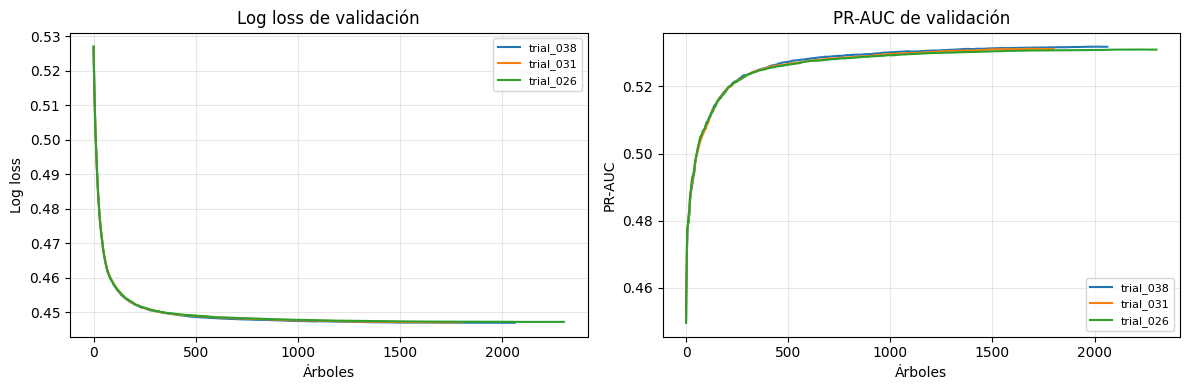

In [12]:
# Curvas conservadas del experimento original (solo candidatos ajustados).
fig, ax = plt.subplots(1,2,figsize=(12,4))
for candidate in candidates[1:]:
    curve_file = CAND_DIR/candidate["name"]/"learning_curve.json"
    if not curve_file.exists():continue
    ev=json.loads(curve_file.read_text())["val"]
    for panel,metric in zip(ax,["binary_logloss","average_precision"]):
        panel.plot(ev[metric],label=candidate["name"])
ax[0].set(title="Log loss de validación",xlabel="Árboles",ylabel="Log loss")
ax[1].set(title="PR-AUC de validación",xlabel="Árboles",ylabel="PR-AUC")
for panel in ax:panel.grid(alpha=.3);panel.legend(fontsize=8)
fig.tight_layout();fig.savefig(FIG_DIR/"tuning_learning_curves.png",dpi=130);plt.show()

## 6. Seleccionar por validación (antes de abrir prueba)

Si Optuna no supera al B1 original, **B1 puede ganar**. El conjunto de prueba no participa en la selección.

In [13]:
selected = max(candidates, key=lambda c: float(average_precision_score(y_val,c["p_val"])))
best_tuned = max([c for c in candidates if c["trial"] is not None],
                 key=lambda c: float(average_precision_score(y_val,c["p_val"])))
selected_thr = float(me.best_cost_threshold(y_val,selected["p_val"],COST_FP,COST_FN))
choice = {
    "selected_name":selected["name"],"selected_trial":selected["trial"],
    "selected_by":"pr_auc_validation", "numeric_dtype":"float64",
    "selected_pr_auc_val":float(average_precision_score(y_val,selected["p_val"])),
    "baseline_pr_auc_val":float(average_precision_score(y_val,P_B1_VAL)),
    "best_tuned_name":best_tuned["name"],"best_tuned_pr_auc_val":float(average_precision_score(y_val,best_tuned["p_val"])),
    "decision_threshold_validation":selected_thr,
    "decision_threshold_deployment":float(COST_FP/(COST_FP+COST_FN)) if RUN_REFIT else selected_thr,
    "run_id":RUN_ID, "n_trials":len(study.trials),
    "reason":"Se seleccionó por validación, nunca por prueba. XGBoost no forma parte del tuning LightGBM.",
}
(OUT_DIR/"selection_validation.json").write_text(json.dumps(choice,indent=2,ensure_ascii=False))
print("✔ SELECCIÓN POR VALIDACIÓN:",selected["name"],"PR-AUC:",choice["selected_pr_auc_val"])
print("Umbral aprendido en validación:",selected_thr)

✔ SELECCIÓN POR VALIDACIÓN: trial_038 PR-AUC: 0.5318380036455427
Umbral aprendido en validación: 0.25591016998639843


## 7. Prueba (una única evaluación comparativa)

Se utiliza test **después de la selección por validación**. El objetivo es comparar el candidato ajustado, el B1 original y la configuración seleccionada. No se elige modelo a partir de resultados de prueba.

In [14]:
# FlightDate, hora y categorías se conservan para generar Gold sin volver a leer Silver.
test_with_meta = load_compact("test",extra=["FlightDate","dep_hour"])
y_test = test_with_meta.pop(TARGET).to_numpy(dtype=np.uint8,copy=True)
assert np.array_equal(y_test, Y_B1_TEST), "Orden de prueba no coincide con B1 float64"
test_df = test_with_meta[FULL]

compare_test = []
p_test_by_name = {}
for cand in [candidates[0],best_tuned] if selected["name"] in (candidates[0]["name"],best_tuned["name"]) else [candidates[0],best_tuned,selected]:
    if cand["name"] == candidates[0]["name"]:
        p_test = P_B1_TEST
    else:
        p_test = cand["booster"].predict(test_df, num_iteration=cand["best_iteration"])
    p_test_by_name[cand["name"]] = p_test
    thr = float(me.best_cost_threshold(y_val,cand["p_val"],COST_FP,COST_FN))
    metrics = me.evaluate_model(cand["name"],y_test,p_test,thr,COST_FP,COST_FN)
    metrics["costo_x1000_umbral_comun"] = me.evaluate_model(cand["name"],y_test,p_test,
        COST_FP/(COST_FP+COST_FN),COST_FP,COST_FN)["costo_x1000"]
    metrics["best_iteration"] = cand["best_iteration"]
    compare_test.append(metrics)
results_test = pd.DataFrame(compare_test).set_index("modelo")
results_test.to_csv(OUT_DIR/"tuning_test_comparison.csv")
display(results_test)

p_a = p_test_by_name[best_tuned["name"]]
p_b = P_B1_TEST
pr_diff,pr_lo,pr_hi = me.paired_bootstrap_diff(y_test,p_a,p_b,average_precision_score,BOOT_N,BOOT_ROWS,SEED)
roc_diff,roc_lo,roc_hi = me.paired_bootstrap_diff(y_test,p_a,p_b,roc_auc_score,BOOT_N,BOOT_ROWS,SEED)
bootstrap = {"comparison":"best_tuned_minus_B1", "pr_auc":pr_diff,"pr_auc_95ci":[pr_lo,pr_hi],
    "roc_auc":roc_diff,"roc_auc_95ci":[roc_lo,roc_hi],"n_boot":BOOT_N,"rows":BOOT_ROWS}
(OUT_DIR/"tuning_bootstrap_test.json").write_text(json.dumps(bootstrap,indent=2))
print("Bootstrap (mejor ajustado - B1) PR-AUC:",bootstrap["pr_auc"],bootstrap["pr_auc_95ci"])

 test: 20/20 fragmentos
✔ test: 1,000,000 filas / 0.25 GiB / 2.0s


,umbral,roc_auc,pr_auc,precision,recall,f1,lift_precision,alertas_%,costo_x1000,TP,FP,FN,TN,brier,log_loss,ece,costo_x1000_umbral_comun,best_iteration
modelo,,,,,,,,,,,,,,,,,,
B1_baseline_float64,0.249884,0.759279,0.544631,0.446365,0.601251,0.512359,1.946924,0.308821,445.234,137847,170974,91420,599759,0.143378,0.450892,0.002197,445.243,930
trial_038,0.255910,0.761479,0.547792,0.453277,0.595014,0.514564,1.977072,0.300957,443.090,136417,164540,92850,606193,0.142875,0.449411,0.001792,442.567,1963


Bootstrap (mejor ajustado - B1) PR-AUC: 0.003267010093795153 [0.0026301456700635025, 0.0038132750462090276]


## 8. Reentrenamiento train+val (modelo definitivo)

Se conservan los **árboles elegidos por early stopping de validación** y se reentrena sobre 5M registros sin consultar test para ajustar hiperparámetros. El umbral común por costos, `1/(1+3)=0,25`, es el umbral documentado para el modelo reentrenado; no se recalibra con prueba.

**IMPORTANTE:** si el laboratorio se cierra después del refit, `model.txt` y `refit_config.json` permiten retomarlo sin repetir entrenamiento.

In [15]:
MODEL_VERSION = f"lgbm-f64-seed42-h240-{RUN_ID}-{selected['name'].replace('_','-')}"
MODEL_DIR = REGISTRY_ROOT / MODEL_VERSION
MODEL_DIR.mkdir(parents=True,exist_ok=True)
DEPLOY_MODEL_FILE = MODEL_DIR / "model.txt"
REFIT_CONFIG_FILE = MODEL_DIR / "refit_config.json"
if DEPLOY_MODEL_FILE.exists() and REFIT_CONFIG_FILE.exists():
    final_booster = lgb.Booster(model_file=str(DEPLOY_MODEL_FILE))
    saved_refit = json.loads(REFIT_CONFIG_FILE.read_text())
    assert saved_refit["selected_name"] == selected["name"]
    assert saved_refit["selected_best_iteration"] == int(selected["best_iteration"])
    print("✔ Refit recuperado del disco sin entrenar otra vez:", MODEL_DIR)
else:
    start = time.time()
    if RUN_REFIT:
        combined = pd.concat([train_df,val_df],ignore_index=True)
        combined_y = np.concatenate([y_train,y_val])
        refit_params = {**BASE,**selected["params"],"metric":"binary_logloss"}
        refit_params["min_data_in_leaf"] = max(20,int(selected["params"]["min_data_in_leaf"]*len(combined)/len(train_df)))
        dboth = lgb.Dataset(combined,label=combined_y,params=DS_PARAMS,free_raw_data=False)
        final_booster = lgb.train(refit_params,dboth,num_boost_round=int(selected["best_iteration"]))
        del dboth, combined, combined_y;gc.collect()
    else:
        refit_params = {**BASE,**selected["params"]}
        final_booster = selected["booster"]
    final_booster.save_model(str(DEPLOY_MODEL_FILE))
    cfg_refit = {"selected_name":selected["name"],"selected_trial":selected["trial"],
        "selected_best_iteration":int(selected["best_iteration"]),"refitted_train_val":RUN_REFIT,
        "train_rows":N_TRAIN,"val_rows":N_EVAL,"numeric_dtype":"float64", "params":refit_params,
        "seconds":round(time.time()-start,2)}
    REFIT_CONFIG_FILE.write_text(json.dumps(cfg_refit,indent=2,ensure_ascii=False,default=float))
    print("✔ Modelo final entrenado y guardado:", MODEL_DIR, "segundos:",cfg_refit["seconds"])
assert final_booster.feature_name() == FULL
p_final_test = final_booster.predict(test_df)
np.savez_compressed(OUT_DIR/"deployed_model_test_predictions.npz",y=y_test,p=p_final_test)
refit_comparison = pd.DataFrame([
    me.evaluate_model("Seleccionado antes de refit",y_test,p_test_by_name[selected["name"]],COST_FP/(COST_FP+COST_FN),COST_FP,COST_FN),
    me.evaluate_model("Modelo definitivo (train+val)" if RUN_REFIT else "Modelo definitivo (train)",
        y_test,p_final_test,COST_FP/(COST_FP+COST_FN),COST_FP,COST_FN),
]).set_index("modelo")
refit_comparison.to_csv(OUT_DIR/"tuning_refit_test_comparison.csv")
display(refit_comparison[["roc_auc","pr_auc","brier","log_loss","precision","recall","f1","costo_x1000"]])

✔ Modelo final entrenado y guardado: ../outputs/model_registry/lgbm-f64-seed42-h240-20261122T031926Z-trial-038 segundos: 761.2


,roc_auc,pr_auc,brier,log_loss,precision,recall,f1,costo_x1000
modelo,,,,,,,,
Seleccionado antes de refit,0.761479,0.547792,0.142875,0.449411,0.447325,0.606206,0.514785,442.567
Modelo definitivo (train+val),0.764444,0.552384,0.142121,0.447398,0.452749,0.606297,0.518392,438.807


## 9. Contrato de inferencia y paquete para SageMaker

Genera `model.tar.gz` con `model.txt`, `feature_schema.json`, `metadata.json`, `code/inference.py` y `code/requirements.txt`. El servicio **recibe características ya calculadas**, en el mismo orden y niveles categóricos de B1. Una solicitud cruda con aerolínea/origen/hora **no basta**: el cómputo de históricas, congestión y rotación a T−240 minutos deberá realizarse antes del endpoint.

El contrato no utiliza `DepDel15` como predictor y se prueba localmente para comprobar que su probabilidad coincida con LightGBM. El despliegue se hará en una etapa posterior con un contenedor compatible que instale LightGBM.

In [16]:
import importlib.util

# Contrato reutilizado por el contenedor de SageMaker.
INFERENCE_SOURCE = '"""Contrato de inferencia SageMaker para LightGBM BTS.\n\nLas variables ya deben estar calculadas para 240 minutos antes de la salida.\nNo acepta filas crudas de BTS, ni genera historia/ASOF automáticamente.\n"""\nimport json\nfrom pathlib import Path\n\nimport lightgbm as lgb\nimport numpy as np\nimport pandas as pd\n\n\ndef model_fn(model_dir):\n    root = Path(model_dir)\n    with (root / "feature_schema.json").open(encoding="utf-8") as f:\n        schema = json.load(f)\n    with (root / "metadata.json").open(encoding="utf-8") as f:\n        metadata = json.load(f)\n    booster = lgb.Booster(model_file=str(root / "model.txt"))\n    assert booster.feature_name() == schema["feature_names"], "Orden de variables incompatible"\n    return {"booster": booster, "schema": schema, "metadata": metadata}\n\n\ndef input_fn(request_body, request_content_type):\n    if request_content_type.split(";")[0].strip().lower() != "application/json":\n        raise ValueError("Usa ContentType=application/json")\n    payload = json.loads(request_body)\n    if not isinstance(payload, dict):\n        raise ValueError("Se espera un objeto JSON")\n    if "features" in payload:\n        rows = [payload["features"]]\n    elif "instances" in payload:\n        rows = payload["instances"]\n    else:\n        raise ValueError("Usa {\\"features\\": {...}} o {\\"instances\\": [{...}, ...]}")\n    if not isinstance(rows, list) or not rows or len(rows) > 100:\n        raise ValueError("instances debe contener de 1 a 100 registros")\n    if any(not isinstance(row, dict) for row in rows):\n        raise ValueError("Cada registro debe ser un objeto JSON")\n    return rows\n\n\ndef predict_fn(input_data, model):\n    schema = model["schema"]\n    names = schema["feature_names"]\n    cats = schema["cat_cols"]\n    levels = schema["cat_levels"]\n    cleaned = []\n    for row in input_data:\n        missing = set(names) - set(row)\n        extra = set(row) - set(names)\n        if missing or extra:\n            raise ValueError(f"Variables faltantes: {sorted(missing)}. No admitidas: {sorted(extra)}")\n        cleaned.append({k: row[k] for k in names})\n    frame = pd.DataFrame(cleaned, columns=names)\n    for col in names:\n        if col in cats:\n            frame[col] = pd.Categorical(frame[col], categories=levels[col])\n        else:\n            frame[col] = pd.to_numeric(frame[col], errors="raise").astype("float64")\n    p = np.asarray(model["booster"].predict(frame), dtype=float)\n    metadata = model["metadata"]\n    threshold = float(metadata["decision_threshold"])\n    return {\n        "model_version": metadata["model_version"],\n        "prediction_horizon_min": int(metadata["prediction_horizon_minutes"]),\n        "predictions": [\n            {"probability_delay_15min": float(x), "alert": bool(x >= threshold)}\n            for x in p\n        ],\n        "decision_threshold": threshold,\n    }\n\n\ndef output_fn(prediction, accept):\n    if accept.split(";")[0].strip().lower() not in ("application/json", "*/*"):\n        raise ValueError("El endpoint responde application/json")\n    return json.dumps(prediction, ensure_ascii=False, allow_nan=False), "application/json"\n'
code_dir = MODEL_DIR / "code"
code_dir.mkdir(exist_ok=True)
(code_dir / "inference.py").write_text(INFERENCE_SOURCE, encoding="utf-8")
(code_dir / "requirements.txt").write_text(f"lightgbm=={lgb.__version__}\n",encoding="utf-8")
shutil.copyfile(B1_DIR/"feature_schema.json",MODEL_DIR/"feature_schema.json")

threshold = COST_FP/(COST_FP+COST_FN) if RUN_REFIT else selected_thr
metadata = {
    "model_version":MODEL_VERSION, "family":"LightGBM", "source":"BTS stage_A seeded sample",
    "target":"DepDel15", "prediction_horizon_minutes":240,
    "input_contract":"engineered_features_only", "engineered_features_required":True,
    "feature_order":FULL, "selection_metric":"PR-AUC validation", "selected_candidate":selected["name"],
    "selected_val_pr_auc":float(choice["selected_pr_auc_val"]),
    "comparison_xgboost_baseline_val_pr_auc":0.531467,
    "train_rows":N_TRAIN, "validation_rows":N_EVAL, "test_rows":N_EVAL,
    "train_end":"2024-12-31", "validation_end":"2025-08-31",
    "refitted_train_and_validation":bool(RUN_REFIT),
    "decision_threshold":float(threshold),"cost_fp":COST_FP,"cost_fn":COST_FN,
    "lightgbm_version":lgb.__version__,"numeric_dtype":"float64",
    "model_file":"model.txt", "created_utc":datetime.now(timezone.utc).isoformat(),
    "notes":"XGBoost mejoró el PR-AUC inicial; se priorizó LightGBM por eficiencia. La selección de LightGBM óptimo no utiliza prueba.",
}
(MODEL_DIR/"metadata.json").write_text(json.dumps(metadata,indent=2,ensure_ascii=False))

example = test_df.iloc[0]
def scalar_json(x):
    if pd.isna(x): return None
    if isinstance(x,(np.integer,int)): return int(x)
    if isinstance(x,(np.floating,float)): return float(x)
    if isinstance(x,(np.bool_,bool)): return bool(x)
    return str(x)
request = {"features":{k:scalar_json(example[k]) for k in FULL}}
(MODEL_DIR/"sample_request.json").write_text(json.dumps(request,ensure_ascii=False,indent=2,allow_nan=False))

spec = importlib.util.spec_from_file_location("bts_lightgbm_inference",str(code_dir/"inference.py"))
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)
loaded = module.model_fn(str(MODEL_DIR))
parsed = module.input_fn(json.dumps(request),"application/json")
output = module.predict_fn(parsed,loaded)
assert np.isclose(output["predictions"][0]["probability_delay_15min"],p_final_test[0],atol=1e-8)
assert "DepDel15" not in request["features"]
body,content_type = module.output_fn(output,"application/json")
assert content_type == "application/json" and json.loads(body)["predictions"]

MODEL_ARCHIVE = MODEL_DIR/"model.tar.gz"
with tarfile.open(MODEL_ARCHIVE,"w:gz") as tar:
    for relative in ["model.txt","feature_schema.json","metadata.json","code/inference.py","code/requirements.txt"]:
        tar.add(str(MODEL_DIR/relative),arcname=relative)
with tarfile.open(MODEL_ARCHIVE,"r:gz") as tar:
    assert {"model.txt","feature_schema.json","metadata.json","code/inference.py","code/requirements.txt"}.issubset(tar.getnames())
print("✔ Paquete validado:",MODEL_ARCHIVE, "MiB:",round(MODEL_ARCHIVE.stat().st_size/1024**2,2))
print("✔ Solicitud ejemplo:",MODEL_DIR/"sample_request.json")
print("✔ Predicción comprobada localmente:",output)
(OUT_DIR/"model_version.json").write_text(json.dumps({"model_version":MODEL_VERSION,"model_dir":str(MODEL_DIR.resolve()),
    "archive_sha256":hashlib.sha256(MODEL_ARCHIVE.read_bytes()).hexdigest()},indent=2))

✔ Paquete validado: ../outputs/model_registry/lgbm-f64-seed42-h240-20261122T031926Z-trial-038/model.tar.gz MiB: 4.48
✔ Solicitud ejemplo: ../outputs/model_registry/lgbm-f64-seed42-h240-20261122T031926Z-trial-038/sample_request.json
✔ Predicción comprobada localmente: {'model_version': 'lgbm-f64-seed42-h240-20261122T031926Z-trial-038', 'prediction_horizon_min': 240, 'predictions': [{'probability_delay_15min': 0.1232693936551733, 'alert': False}], 'decision_threshold': 0.25}


274

In [7]:

from pathlib import Path
import json

ROOT = Path("/home/ec2-user/SageMaker")

info_path = ROOT / "outputs/outputs_modeling/tuning_lightgbm_float64/model_version.json"
gold_path = ROOT / "data/gold/pred_vs_real/meta.json"

model_info = json.loads(info_path.read_text())
gold_meta = json.loads(gold_path.read_text())

version = model_info["model_version"]
nombre = "LightGBM (float64)"

# Etiquetas del análisis C
gold_meta["modelo"] = nombre
gold_meta["model_version"] = version

# Metadatos del conjunto de prueba
gold_meta["conjuntos"]["prueba"]["modelo"] = nombre
gold_meta["conjuntos"]["prueba"]["model_version"] = version

gold_path.write_text(
    json.dumps(gold_meta, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("✔ Metadatos actualizados")
print("Modelo:", gold_meta["modelo"])
print("Versión:", gold_meta["model_version"])


✔ Metadatos actualizados
Modelo: LightGBM (float64)
Versión: lgbm-f64-seed42-h240-20261122T031926Z-trial-038


## 10. Generar las cuatro tablas Gold **del modelo definitivo**

Estas tablas son nuevas respecto de la etapa C, que compara los cuatro **modelos originales**. Gold representa el **modelo refit final** y alimentará el análisis posterior de `flight_delay_analisis_etapa_C_definitivo_aws.ipynb` (Parte II). Se guardan en `../data/gold/pred_vs_real/` y posteriormente se publican en `s3://bts-flights-analysis/gold/pred_vs_real/`. No cambies la selección con métricas de prueba.

In [2]:

from pathlib import Path
from datetime import datetime, timezone
import json
import boto3
import duckdb
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss
)

# Rutas persistentes
OUT_DIR = Path("../outputs/outputs_modeling/tuning_lightgbm_float64")
GOLD_DIR = Path("../data/gold/pred_vs_real")
PARTS_DIR = Path("../data/checkpoints/features_seed42_h240_chunk50000/test")
BUCKET = "bts-flights-analysis"

# Recuperar modelo definitivo
model_info = json.loads(
    (OUT_DIR / "model_version.json").read_text()
)
model_dir = Path(model_info["model_dir"])
metadata = json.loads(
    (model_dir / "metadata.json").read_text()
)

COST_FP = int(metadata["cost_fp"])
COST_FN = int(metadata["cost_fn"])

# Recuperar predicciones sin cargar ni entrenar el modelo
with np.load(
    OUT_DIR / "deployed_model_test_predictions.npz"
) as saved:
    y_test = saved["y"].copy()
    p_final_test = saved["p"].copy()

# Recuperar únicamente columnas necesarias para Gold
cols = [
    "FlightDate", "Reporting_Airline", "Origin",
    "dep_hour", "Month", "DayOfWeek", "DepDel15"
]

files = sorted(PARTS_DIR.glob("part_*.parquet"))
assert len(files) == 20, f"Fragmentos encontrados: {len(files)}"

test_with_meta = pd.concat(
    [pq.read_table(str(f), columns=cols).to_pandas()
     for f in files],
    ignore_index=True
)

assert np.array_equal(
    test_with_meta["DepDel15"].to_numpy(dtype=np.uint8),
    y_test
), "Las etiquetas no coinciden con las predicciones guardadas"

print("✔ Modelo:", metadata["model_version"])
print("✔ Predicciones recuperadas:", len(p_final_test))
print("✔ Datos de prueba alineados")
print("✔ Puedes ejecutar la sección 10 sin reentrenar")


✔ Modelo: lgbm-f64-seed42-h240-20261122T031926Z-trial-038
✔ Predicciones recuperadas: 1000000
✔ Datos de prueba alineados
✔ Puedes ejecutar la sección 10 sin reentrenar


In [8]:
import duckdb
from botocore.exceptions import ClientError

# Sincroniza Gold previo para conservar otros conjuntos (p. ej. prospectivo).
# Si ya existe una copia local completa, las credenciales caducadas NO bloquean la creación local.
GOLD_DIR.mkdir(parents=True, exist_ok=True)
GOLD_TABLE_NAMES = ["group_metrics","score_bins","timeseries","heat_hora_dia"]
local_complete = all((GOLD_DIR/f"{name}.parquet").is_file() for name in GOLD_TABLE_NAMES) and (GOLD_DIR/"meta.json").is_file()
try:
    _gold_s3 = boto3.Session().client("s3")
    for name in GOLD_TABLE_NAMES:
        key = f"gold/pred_vs_real/{name}/{name}.parquet"
        try:
            _gold_s3.download_file(BUCKET,key,str(GOLD_DIR/f"{name}.parquet"))
        except ClientError as e:
            if e.response.get("Error",{}).get("Code") not in ("404","NoSuchKey","NotFound"): raise
    try:
        _gold_s3.download_file(BUCKET,"gold/pred_vs_real/meta.json",str(GOLD_DIR/"meta.json"))
    except ClientError as e:
        if e.response.get("Error",{}).get("Code") not in ("404","NoSuchKey","NotFound"): raise
except Exception as e:
    if not local_complete:
        raise RuntimeError("No hay copia Gold local completa y no se pudo verificar Gold en S3. "
                           "Renueva credenciales antes de sobrescribir Gold; el modelo ya está guardado.") from e
    print("Aviso: se usará Gold LOCAL completo porque no está disponible S3:",type(e).__name__)

GOLD_THR = float(metadata["decision_threshold"])
GOLD_SET = "prueba"
GOLD_MIN_ROWS = 500
_DOW = ["Lun","Mar","Mié","Jue","Vie","Sáb","Dom"]
_BANDS = ["Madrugada (0–5 h)","Mañana (6–11 h)","Tarde (12–17 h)","Noche (18–24 h)"]
_SEASONS = ["Invierno (dic–feb)","Primavera (mar–may)","Verano (jun–ago)","Otoño (sep–nov)"]
season = lambda m: _SEASONS[0] if m in (12,1,2) else _SEASONS[1] if m in (3,4,5) else _SEASONS[2] if m in (6,7,8) else _SEASONS[3]

gold = pd.DataFrame({
    "fecha":pd.to_datetime(test_with_meta.FlightDate).dt.normalize().values,
    "aerolinea":test_with_meta.Reporting_Airline.astype(str).values,
    "origen":test_with_meta.Origin.astype(str).values,
    "hora":test_with_meta.dep_hour.astype(int).values,
    "mes":test_with_meta.Month.astype(int).values,
    "dia_semana":test_with_meta.DayOfWeek.astype(int).values,
    "y":y_test, "p":p_final_test,
})
gold["periodo"] = pd.to_datetime(gold.fecha).dt.strftime("%Y-%m")
gold["franja"] = pd.cut(gold.hora,[-1,5,11,17,24],labels=_BANDS).astype(str)
gold["temporada"] = gold.mes.map(season)
gold["dia_nombre"] = gold.dia_semana.map(lambda d:_DOW[d-1])
gold["hora_txt"] = gold.hora.map(lambda h:f"{h:02d} h")
gold["alerta"] = (gold.p>=GOLD_THR).astype(int)
for col,a,b in [("tp",1,1),("fp",1,0),("fn",0,1),("tn",0,0)]:
    gold[col] = ((gold.alerta==a)&(gold.y==b)).astype(int)

def gold_group_table(dimension,col,order=None,min_rows=GOLD_MIN_ROWS):
    key = gold[col] if col else pd.Series("Todos los vuelos",index=gold.index)
    rows=[]
    for k,g in gold.groupby(key,observed=True,sort=False):
        n,pos=len(g),int(g.y.sum())
        if n < min_rows or pos in (0,n):continue
        tp,fp,fn,tn=(int(g[c].sum()) for c in ("tp","fp","fn","tn"))
        prec=tp/(tp+fp) if tp+fp else 0.
        rec=tp/(tp+fn) if tp+fn else 0.
        rows.append({"dimension":dimension,"grupo":str(k),"vuelos":n,"retrasados":pos,
            "tasa_real":pos/n,"prob_media":float(g.p.mean()),"sesgo":float(g.p.mean())/(pos/n),
            "roc_auc":roc_auc_score(g.y,g.p),"pr_auc":average_precision_score(g.y,g.p),
            "brier":brier_score_loss(g.y,g.p),"umbral":GOLD_THR,"alertas":tp+fp,
            "tp":tp,"fp":fp,"fn":fn,"tn":tn,"precision":prec,"recall":rec,
            "f1":2*prec*rec/(prec+rec) if prec+rec else 0.})
    t=pd.DataFrame(rows)
    if len(t):t["orden"]=t.grupo.map(order) if order else t.vuelos.rank(ascending=False,method="first")
    return t

_dims=[("Global",None,None),("Aerolínea","aerolinea",None),("Aeropuerto de origen","origen",None),
    ("Franja horaria","franja",{b:i for i,b in enumerate(_BANDS)}),
    ("Temporada","temporada",{b:i for i,b in enumerate(_SEASONS)}),
    ("Mes","periodo",{m:i for i,m in enumerate(sorted(gold.periodo.unique()))}),
    ("Día de la semana","dia_nombre",{d:i for i,d in enumerate(_DOW)}),
    ("Hora de salida","hora_txt",{f"{h:02d} h":h for h in range(25)})]
gold_tables={
    "group_metrics":pd.concat([gold_group_table(d,c,o,1 if d=="Global" else GOLD_MIN_ROWS) for d,c,o in _dims],ignore_index=True),
    "score_bins":(gold.assign(bin=pd.qcut(gold.p.rank(method="first"),100,labels=False)).groupby("bin")
        .agg(p_min=("p","min"),p_max=("p","max"),p_media=("p","mean"),
             vuelos=("y","size"),retrasados=("y","sum")).reset_index()),
    "timeseries":(gold.groupby("fecha").agg(vuelos=("y","size"),retrasados=("y","sum"),
        prob_suma=("p","sum"),alertas=("alerta","sum"),tp=("tp","sum"),fp=("fp","sum")).reset_index()),
    "heat_hora_dia":(gold.groupby(["hora","dia_semana"]).agg(vuelos=("y","size"),
        retrasados=("y","sum"),prob_suma=("p","sum")).reset_index()),
}
assert gold_tables["score_bins"].vuelos.sum()==len(gold)==gold_tables["timeseries"].vuelos.sum()

def write_gold(tables,gold_dir,conjunto):
    c=duckdb.connect()
    for name,df in tables.items():
        path=gold_dir/f"{name}.parquet"
        df=df.assign(conjunto=conjunto)
        if path.exists():
            old=c.execute(f"SELECT * FROM read_parquet('{path.as_posix()}') WHERE conjunto <> ?",[conjunto]).df()
            df=pd.concat([old,df],ignore_index=True)
        c.register("t",df)
        c.execute(f"COPY t TO '{path.as_posix()}.tmp' (FORMAT PARQUET, COMPRESSION ZSTD)")
        c.unregister("t")
        Path(f"{path.as_posix()}.tmp").replace(path)
    c.close()
write_gold(gold_tables,GOLD_DIR,GOLD_SET)

meta_p=GOLD_DIR/"meta.json"
meta=json.loads(meta_p.read_text()) if meta_p.exists() else {"conjuntos":{}}
meta["modelo"] = metadata["model_version"]
meta.update({"costo_fp":COST_FP,"costo_fn":COST_FN,"horizonte_min":240,
             "train_end":"2024-12-31","val_end":"2025-08-31"})
meta.setdefault("conjuntos",{})[GOLD_SET]={
    "desde":str(gold.fecha.min().date()),"hasta":str(gold.fecha.max().date()),
    "vuelos_muestra":int(len(gold)),"vuelos_poblacion":None,
    "umbral":GOLD_THR,"generado":datetime.now(timezone.utc).isoformat(),
    "modelo":metadata["model_version"]}
meta_p.write_text(json.dumps(meta,indent=2,ensure_ascii=False))
print("✔ Gold generado:",[(k,len(t)) for k,t in gold_tables.items()])
# DDL de Athena para las cuatro tablas.
TYPES = {"BIGINT":"bigint", "INTEGER":"int", "SMALLINT":"smallint",
         "TINYINT":"tinyint", "DOUBLE":"double", "FLOAT":"float",
         "VARCHAR":"string", "BOOLEAN":"boolean", "DATE":"date",
         "TIMESTAMP":"timestamp", "TIMESTAMP_NS":"timestamp", "TIMESTAMP_MS":"timestamp"}
ddls = ["CREATE DATABASE IF NOT EXISTS bts_flights;"]
for name in GOLD_TABLE_NAMES:
    path = (GOLD_DIR/f"{name}.parquet").as_posix()
    cols = duckdb.sql(f"DESCRIBE SELECT * FROM read_parquet('{path}')").fetchall()
    TYPES["UBIGINT"] = "BIGINT"
    unknown = [(r[0],r[1]) for r in cols if r[1] not in TYPES]
    assert not unknown, f"Tipos sin correspondencia: {unknown}"
    body = ",\n  ".join(f"`{r[0]}` {TYPES[r[1]]}" for r in cols)
    ddls.append(f"CREATE EXTERNAL TABLE IF NOT EXISTS bts_flights.gold_{name} (\n  {body}\n)\n"
        f"STORED AS PARQUET\nLOCATION 's3://{BUCKET}/gold/pred_vs_real/{name}/';")
(OUT_DIR/"athena_gold_ddl.sql").write_text("\n\n".join(ddls)+"\n",encoding="utf-8")
print("✔ DDL de Athena escrito")

✔ Gold generado: [('group_metrics', 230), ('score_bins', 100), ('timeseries', 365), ('heat_hora_dia', 168)]
✔ DDL de Athena escrito


## 11. Subida oficial a S3 (independiente, ejecutar incluso tras renovar credenciales)

Esta celda puede ejecutarse **en un notebook nuevo sin ejecutar las anteriores**. Recupera rutas únicamente desde archivos locales. Publica: (a) `study.sqlite3`/resultados/figuras, (b) paquete versionado `model.tar.gz`, (c) cuatro tablas Gold y metadatos. **No sustituye la etapa C**; la capa Gold se actualiza al modelo final. Para mayor seguridad, esta celda verifica los archivos antes de sobrescribir Gold.

In [9]:
# Esta celda es AUTÓNOMA: no necesita variables de los entrenamientos anteriores.
from pathlib import Path
import json, boto3, sqlite3

BUCKET_UPLOAD = "bts-flights-analysis"
OUTPUT_ROOT = Path("/home/ec2-user/SageMaker/outputs/outputs_modeling/tuning_lightgbm_float64")
GOLD_ROOT = Path("/home/ec2-user/SageMaker/data/gold/pred_vs_real")
REGISTRY_ROOT_UPLOAD = Path("/home/ec2-user/SageMaker/outputs/model_registry")
TUNING_PREFIX = "modeling/tuning/lightgbm-float64-seed42-h240/"

model_info = json.loads((OUTPUT_ROOT/"model_version.json").read_text())
model_version = model_info["model_version"]
model_dir = REGISTRY_ROOT_UPLOAD/model_version
assert (model_dir/"model.tar.gz").is_file(), "Primero empaqueta el modelo final"
required_gold = [GOLD_ROOT/f"{t}.parquet" for t in ("group_metrics","score_bins","timeseries","heat_hora_dia")]
required_gold += [GOLD_ROOT/"meta.json"]
assert all(f.is_file() and f.stat().st_size for f in required_gold), "Gold no está completo"

s3 = boto3.Session().client("s3")
print("Autenticado:",boto3.Session().client("sts").get_caller_identity()["Arn"])

# Siempre sube primero las evidencias, incluida copia consistente de SQLite.
db = OUTPUT_ROOT/"study.sqlite3"
if db.exists():
    backup = OUTPUT_ROOT/"study_backup.sqlite3"
    with sqlite3.connect(str(db)) as src:
        with sqlite3.connect(str(backup)) as dst:src.backup(dst)
for f in OUTPUT_ROOT.rglob("*"):
    if not f.is_file() or f.name == "study.sqlite3":continue
    key = TUNING_PREFIX+f.relative_to(OUTPUT_ROOT).as_posix()
    s3.upload_file(str(f),BUCKET_UPLOAD,key)
    print("Tuning:",key)

# Después sube el paquete y el contrato de inferencia versionado.
for f in model_dir.rglob("*"):
    if not f.is_file():continue
    key = f"models/flight-delay/{model_version}/"+f.relative_to(model_dir).as_posix()
    s3.upload_file(str(f),BUCKET_UPLOAD,key)
    print("Modelo:",key)

# Gold se publica solamente tras comprobar que los cinco archivos existen.
for f in required_gold:
    key = ("gold/pred_vs_real/meta.json" if f.name=="meta.json" else
           f"gold/pred_vs_real/{f.stem}/{f.name}")
    s3.upload_file(str(f),BUCKET_UPLOAD,key)
    print("Gold:",key)
ddl = OUTPUT_ROOT / "athena_gold_ddl.sql"
if ddl.is_file():
    s3.upload_file(str(ddl),BUCKET_UPLOAD,"modeling/outputs_modeling/athena_gold_ddl.sql")
print("✔ Modelo SageMaker: s3://"+BUCKET_UPLOAD+"/models/flight-delay/"+model_version+"/model.tar.gz")
print("✔ Resultados Optuna: s3://"+BUCKET_UPLOAD+"/"+TUNING_PREFIX)
print("✔ Gold definitivo: s3://"+BUCKET_UPLOAD+"/gold/pred_vs_real/")

Autenticado: arn:aws:sts::211125468543:assumed-role/LabRole/SageMaker
Tuning: modeling/tuning/lightgbm-float64-seed42-h240/tuning_refit_test_comparison.csv
Tuning: modeling/tuning/lightgbm-float64-seed42-h240/run_id.txt
Tuning: modeling/tuning/lightgbm-float64-seed42-h240/deployed_model_test_predictions.npz
Tuning: modeling/tuning/lightgbm-float64-seed42-h240/tuning_test_comparison.csv
Tuning: modeling/tuning/lightgbm-float64-seed42-h240/tuning_validation_comparison.csv
Tuning: modeling/tuning/lightgbm-float64-seed42-h240/athena_gold_ddl.sql
Tuning: modeling/tuning/lightgbm-float64-seed42-h240/model_version.json
Tuning: modeling/tuning/lightgbm-float64-seed42-h240/tuning_bootstrap_test.json
Tuning: modeling/tuning/lightgbm-float64-seed42-h240/selection_validation.json
Tuning: modeling/tuning/lightgbm-float64-seed42-h240/study_backup.sqlite3
Tuning: modeling/tuning/lightgbm-float64-seed42-h240/tuning_trials.csv
Tuning: modeling/tuning/lightgbm-float64-seed42-h240/figures/tuning_learning

## 12. Siguiente etapa: endpoint de SageMaker

Este notebook **no crea un endpoint ni deja instancias cobrando**. El paquete preparado contiene el modelo y su script de inferencia. Para desplegarlo, se usará un contenedor de SageMaker compatible con script de inferencia, por ejemplo Scikit-learn `SKLearnModel` con `entry_point="inference.py"`, `source_dir` apuntando a `MODEL_DIR/code` y `model_data` al `model.tar.gz` de S3. **Debe instalar la versión de LightGBM especificada en `code/requirements.txt`**; para entornos sin salida a PyPI se necesitará una imagen personalizada con LightGBM preinstalado.

**Entrada de ejemplo:** `sample_request.json` (`{"features": {...}}`) o batch `{"instances": [{...}]}`. **Respuesta:** `probability_delay_15min`, `alert`, `decision_threshold`. Las características históricas deben generarse fuera del endpoint sin fuga de información y con corte a T−240 minutos. Prueba `sample_request.json` en una invocación real antes de conectar un front-end.

**Entregables de tuning**: `tuning_trials.csv`, `tuning_validation_comparison.csv`, `selection_validation.json`, `tuning_test_comparison.csv`, `tuning_bootstrap_test.json`, `tuning_refit_test_comparison.csv`, `deployed_model_test_predictions.npz`, estudio SQLite, figuras y paquete de modelo.